# Task 3: recomendación de camas, robustez y defensa de la decisión
CC2017 Modelación y Simulación, UVG · Hoja de Trabajo 7 · Grupo 5. **Estado: hecho (3.1); 3.2 y 3.3 se redactan en el informe con estos resultados.**

| Inciso | Requisito (hoja) |
|---|---|
| 3.1a | Menor número de camas que cumple (sin espera) bloqueo ≤ 2 % y (con espera) Wq ≤ 6 horas, con teoría y verificado por simulación; recomendar una variante y un número de camas |
| 3.1b | Robustez en tres escenarios: estancia +25 %, llegadas +15 %, CS = 2; camas necesarias para cada meta y por qué una meta cambia menos que la otra ante la variabilidad |
| 3.1c | Protección durante un cierre de k_off camas: bloqueo durante el cierre en la variante sin espera y decisión de contingencia |
| 3.2 – 3.3 | Conclusión para dos audiencias, preguntas difíciles de la directora y dato real a solicitar (se redactan en el informe) |

**Criterios de decisión (fijados antes de simular):**
- La teoría (Erlang B y Erlang C) da el número de camas cuando es exacta. La simulación lo **verifica**: con el número elegido, el **límite superior** del IC de 95 % debe cumplir la meta, y con una cama menos el **límite inferior** debe incumplirla.
- Donde no hay fórmula exacta (Wq con CS = 2), se decide solo con simulación y se usa el **límite superior** del IC, para no recomendar un número que cumple la meta solo por azar.
- Simulación estacionaria como en el Task 1: horizonte de 11 500 días, calentamiento de 100 días y 30 réplicas. Para CS = 2 se usan 42 000 días y 200 días de calentamiento, como en el Task 2.2.
- Semillas maestras propias de este task, distintas de las del Task 1: 8101 a 8199 (3.1a y 3.1b) y 8301 a 8399 (3.1c).

In [1]:
import sys, json, pathlib, math
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt

RAIZ = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))
from hospital_uci import teoria as T, simulador as S, sir
from hospital_uci import llegadas_variables as LV

FIG, DAT = RAIZ / "resultados" / "figuras", RAIZ / "resultados" / "datos"
FIG.mkdir(parents=True, exist_ok=True); DAT.mkdir(parents=True, exist_ok=True)
AZUL, NARANJA, GRIS = "#0072B2", "#D55E00", "#6b7280"      # azul/naranja: distinguibles con daltonismo
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "grid.linewidth": 0.6, "font.size": 10,
                     "axes.titlesize": 11, "legend.frameon": False})
P = T.parametros_grupo(5)
lam, mu, c = P["lam"], P["mu"], P["c"]
RES = {}      # resultados numéricos de este notebook (se guardan en JSON al final)
k_off = P["k_off"]


In [2]:
# Semillas maestras del Task 3; cada (escenario, c) recibe una distinta y se guardan en resultados/datos/
SEMILLAS = []
def semilla(nombre, s):
    SEMILLAS.append({"corrida": nombre, "semilla_maestra": s})
    return s

HZ, CAL, NREP = 11_500, 100, 30                  # horizonte, calentamiento y réplicas validados en el Task 1.4
HZ_LN, CAL_LN = 42_000, 200                      # CS = 2: horizonte y calentamiento del Task 2.2
META_B, META_WQ_H = 0.02, 6.0                    # metas de la directora


## Task 3.1a: menor número de camas para cada meta
Teoría de la sesión: sin espera, $B(c,a)$ por la recurrencia $B(k,a)=\dfrac{aB(k-1,a)}{k+aB(k-1,a)}$. Con espera, $W_q = \dfrac{C(c,a)\,\rho}{\lambda(1-\rho)}$, con $C=\dfrac{B}{1-\rho(1-B)}$. Se busca el menor $c$ con $B\le 0.02$ y el menor $c$ con $W_q\le 6$ h.

In [3]:
# 3.1a Barrido teórico de c: Erlang B (sin espera) y Wq de M/M/c (con espera, en horas)
def barrido(lam_, mu_, cs=range(16, 31)):
    filas = []
    for k in cs:
        a_ = lam_ / mu_
        wq = T.mmc(lam_, mu_, k)["Wq_h"] if a_ < k else math.inf
        filas.append({"c": k, "B(c,a)": T.erlang_b(k, a_), "Wq (h)": wq})
    return pd.DataFrame(filas)

# 3.1a Menor c que cumple cada meta según la teoría
def c_min(df):
    return int(df.loc[df["B(c,a)"] <= META_B, "c"].min()), int(df.loc[df["Wq (h)"] <= META_WQ_H, "c"].min())

bar = barrido(lam, mu)
cB, cW = c_min(bar)
RES["3.1a_barrido_teoria"] = bar.to_dict("records")
RES["3.1a_c_min_teoria"] = {"sin_espera_B<=2%": cB, "con_espera_Wq<=6h": cW}
print(f"- 3.1a teoría: sin espera, menor c con B <= 2 %: {cB} (B = {T.erlang_b(cB, lam/mu):.4f}; con {cB-1}: {T.erlang_b(cB-1, lam/mu):.4f})")
print(f"- 3.1a teoría: con espera, menor c con Wq <= 6 h: {cW} (Wq = {T.mmc(lam, mu, cW)['Wq_h']:.2f} h; con {cW-1}: {T.mmc(lam, mu, cW-1)['Wq_h']:.2f} h)")
bar.loc[bar["c"].between(17, 26)].round({"B(c,a)": 4, "Wq (h)": 2})

- 3.1a teoría: sin espera, menor c con B <= 2 %: 23 (B = 0.0151; con 22: 0.0232)
- 3.1a teoría: con espera, menor c con Wq <= 6 h: 20 (Wq = 3.54 h; con 19: 6.75 h)


,c,"B(c,a)",Wq (h)
1,17,0.1188,29.87
2,18,0.0911,13.44
3,19,0.0680,6.75
4,20,0.0491,3.54
5,21,0.0343,1.89
6,22,0.0232,1.01
7,23,0.0151,0.53
8,24,0.0095,0.28
9,25,0.0057,0.14
10,26,0.0033,0.07


In [4]:
# 3.1a Verificación por simulación (simulador validado del Task 1): c* y c*-1 para cada meta
def sim_B(c_, lam_=lam, mu_=mu, servicio=None, hz=HZ, cal=CAL, s=None):
    reps = S.replicar(NREP, s, lam=lam_, mu=mu_, c=c_, horizonte=hz, calentamiento=cal, con_espera=False, servicio=servicio)
    return S.ic_t([r["p_bloqueo"] for r in reps])

def sim_Wq(c_, lam_=lam, mu_=mu, servicio=None, hz=HZ, cal=CAL, s=None):
    reps = S.replicar(NREP, s, lam=lam_, mu=mu_, c=c_, horizonte=hz, calentamiento=cal, con_espera=True, servicio=servicio)
    return S.ic_t([24.0 * r["Wq"] for r in reps])            # Wq en horas

ver = []
for k, s in [(cB - 1, 8101), (cB, 8102)]:
    ic = sim_B(k, s=semilla(f"3.1a sin espera c={k}", s))
    ver.append({"meta": "B <= 2 %", "c": k, "teoría": T.erlang_b(k, lam / mu), **{x: ic[x] for x in ("media", "ic_inf", "ic_sup")}})
for k, s in [(cW - 1, 8103), (cW, 8104)]:
    ic = sim_Wq(k, s=semilla(f"3.1a con espera c={k}", s))
    ver.append({"meta": "Wq <= 6 h", "c": k, "teoría": T.mmc(lam, mu, k)["Wq_h"], **{x: ic[x] for x in ("media", "ic_inf", "ic_sup")}})
ver = pd.DataFrame(ver)
ver["teoría en IC"] = (ver["ic_inf"] <= ver["teoría"]) & (ver["teoría"] <= ver["ic_sup"])
lim = ver["meta"].map({"B <= 2 %": META_B, "Wq <= 6 h": META_WQ_H})
ver["cumple (IC sup <= meta)"] = ver["ic_sup"] <= lim
ver["incumple (IC inf > meta)"] = ver["ic_inf"] > lim
RES["3.1a_verificacion_sim"] = ver.to_dict("records")
ver.to_csv(DAT / "task3_1a_verificacion.csv", index=False)
for _, f in ver.iterrows():
    print(f"- 3.1a sim {f['meta']}, c = {f['c']}: {f['media']:.4f} [{f['ic_inf']:.4f}; {f['ic_sup']:.4f}], teoría {f['teoría']:.4f}, "
          f"teoría en IC: {f['teoría en IC']}, cumple: {f['cumple (IC sup <= meta)']}")
ver.round(4)

- 3.1a sim B <= 2 %, c = 22: 0.0232 [0.0227; 0.0237], teoría 0.0232, teoría en IC: True, cumple: False
- 3.1a sim B <= 2 %, c = 23: 0.0150 [0.0147; 0.0154], teoría 0.0151, teoría en IC: True, cumple: True
- 3.1a sim Wq <= 6 h, c = 19: 6.9290 [6.6375; 7.2205], teoría 6.7497, teoría en IC: True, cumple: False
- 3.1a sim Wq <= 6 h, c = 20: 3.4547 [3.3106; 3.5988], teoría 3.5419, teoría en IC: True, cumple: True


,meta,c,teoría,media,ic_inf,ic_sup,teoría en IC,cumple (IC sup <= meta),incumple (IC inf > meta)
0,B <= 2 %,22,0.0232,0.0232,0.0227,0.0237,True,False,True
1,B <= 2 %,23,0.0151,0.0150,0.0147,0.0154,True,True,False
2,Wq <= 6 h,19,6.7497,6.9290,6.6375,7.2205,True,False,True
3,Wq <= 6 h,20,3.5419,3.4547,3.3106,3.5988,True,True,False


In [5]:
# 3.1a Con c = cB camas, ¿cómo queda la otra variante? (para comparar las dos opciones de operación)
REC = cB
alt = {"c_recomendado": REC, "variante": "sin espera",
       "B_con_REC": T.erlang_b(REC, lam / mu), "Wq_h_con_REC_si_hubiera_espera": T.mmc(lam, mu, REC)["Wq_h"],
       "P_esperar_con_REC": T.mmc(lam, mu, REC)["p_esperar"],
       "B_si_se_desviara_con_cW": T.erlang_b(cW, lam / mu), "P_esperar_con_cW": T.mmc(lam, mu, cW)["p_esperar"],
       "Lq_con_cW": T.mmc(lam, mu, cW)["Lq"], "desviados_por_anio_con_REC": 365 * lam * T.erlang_b(REC, lam / mu),
       "desviados_por_anio_con_18": 365 * lam * T.erlang_b(18, lam / mu)}
RES["3.1a_recomendacion"] = alt
print(f"- 3.1a recomendación: variante sin espera con {REC} camas -> B = {alt['B_con_REC']:.4f} "
      f"(≈ {alt['desviados_por_anio_con_REC']:.0f} desviados por año, frente a {alt['desviados_por_anio_con_18']:.0f} con 18 camas)")
print(f"- 3.1a con {REC} camas, si se decidiera esperar: Wq = {alt['Wq_h_con_REC_si_hubiera_espera']:.2f} h y P(esperar) = {alt['P_esperar_con_REC']:.3f}")
print(f"- 3.1a con {cW} camas y espera: P(esperar) = {alt['P_esperar_con_cW']:.3f} y Lq = {alt['Lq_con_cW']:.2f}; con desvío daría B = {alt['B_si_se_desviara_con_cW']:.4f}")

- 3.1a recomendación: variante sin espera con 23 camas -> B = 0.0151 (≈ 21 desviados por año, frente a 126 con 18 camas)
- 3.1a con 23 camas, si se decidiera esperar: Wq = 0.53 h y P(esperar) = 0.043
- 3.1a con 20 camas y espera: P(esperar) = 0.177 y Lq = 0.56; con desvío daría B = 0.0491


## Task 3.1b: robustez en tres escenarios
- (i) Estancia media +25 %: $\mu' = \mu/1.25 = 0.20$.
- (ii) Llegadas +15 %: $\lambda' = 1.15\lambda = 4.37$.
- (iii) Estancia lognormal con CS = 2 y la misma media. Erlang B no depende de la forma de la estancia, solo de su media, así que la meta de bloqueo se sigue calculando con la teoría y se verifica por simulación. Para Wq, Erlang C ya no es exacta y Allen-Cunneen falló por +36 % en el Task 2.2, así que el número de camas se decide por simulación con el límite superior del IC.

En (i) y (ii) la estancia sigue siendo exponencial y la teoría es exacta; se verifica por simulación en el $c$ mínimo de cada meta y en $c-1$.

In [6]:
# 3.1b Escenarios (i) y (ii): teoría exacta (Erlang B y M/M/c) + verificación por simulación en c* y c*-1
ESC = {"base": (lam, mu), "(i) estancia +25 %": (lam, mu / 1.25), "(ii) llegadas +15 %": (1.15 * lam, mu)}
rob, verb = [], []
s0 = 8110
for nombre, (l_, m_) in ESC.items():
    b_ = barrido(l_, m_); kB, kW = c_min(b_)
    rob.append({"escenario": nombre, "a": l_ / m_, "c para B <= 2 %": kB, "c para Wq <= 6 h": kW,
                f"B con {REC} camas": T.erlang_b(REC, l_ / m_), f"Wq (h) con {REC} camas": T.mmc(l_, m_, REC)["Wq_h"], "fuente": "teoría"})
    if nombre == "base":
        continue
    for k in (kB - 1, kB):
        s0 += 1; ic = sim_B(k, l_, m_, s=semilla(f"3.1b {nombre} sin espera c={k}", s0))
        verb.append({"escenario": nombre, "meta": "B <= 2 %", "c": k, "teoría": T.erlang_b(k, l_ / m_), **{x: ic[x] for x in ("media", "ic_inf", "ic_sup")}})
    for k in (kW - 1, kW):
        s0 += 1; ic = sim_Wq(k, l_, m_, s=semilla(f"3.1b {nombre} con espera c={k}", s0))
        verb.append({"escenario": nombre, "meta": "Wq <= 6 h", "c": k, "teoría": T.mmc(l_, m_, k)["Wq_h"], **{x: ic[x] for x in ("media", "ic_inf", "ic_sup")}})
print("- 3.1b escenarios (i) y (ii) listos")

- 3.1b escenarios (i) y (ii) listos


In [7]:
# 3.1b Escenario (iii) CS = 2: estancia lognormal (s² = ln(1 + CS²), m = ln(1/μ) − s²/2), solo simulación
LN = LV.estancia_lognormal(mu, 2.0)
s0 = 8130
for k in (cB - 1, cB):
    s0 += 1; ic = sim_B(k, servicio=LN, hz=HZ_LN, cal=CAL_LN, s=semilla(f"3.1b (iii) CS=2 sin espera c={k}", s0))
    verb.append({"escenario": "(iii) CS = 2", "meta": "B <= 2 %", "c": k, "teoría": T.erlang_b(k, lam / mu), **{x: ic[x] for x in ("media", "ic_inf", "ic_sup")}})
wq_ln = {}
for k in range(cW - 1, cW + 3):
    s0 += 1; ic = sim_Wq(k, servicio=LN, hz=HZ_LN, cal=CAL_LN, s=semilla(f"3.1b (iii) CS=2 con espera c={k}", s0))
    wq_ln[k] = ic
    verb.append({"escenario": "(iii) CS = 2", "meta": "Wq <= 6 h", "c": k, "teoría": T.mmc(lam, mu, k)["Wq_h"] * 2.5,   # Allen-Cunneen: (1+CS²)/2 = 2.5
                 **{x: ic[x] for x in ("media", "ic_inf", "ic_sup")}})
verb = pd.DataFrame(verb)
lim = verb["meta"].map({"B <= 2 %": META_B, "Wq <= 6 h": META_WQ_H})
verb["cumple (IC sup <= meta)"] = verb["ic_sup"] <= lim
kB3 = int(verb.query("escenario == '(iii) CS = 2' and meta == 'B <= 2 %' and `cumple (IC sup <= meta)`")["c"].min())
kW3 = min(k for k, ic in wq_ln.items() if ic["ic_sup"] <= META_WQ_H)
B3 = verb.query("escenario == '(iii) CS = 2' and meta == 'B <= 2 %' and c == @REC").iloc[0]
rob.append({"escenario": "(iii) CS = 2", "a": lam / mu, "c para B <= 2 %": kB3, "c para Wq <= 6 h": kW3,
            f"B con {REC} camas": B3["media"], f"Wq (h) con {REC} camas": float("nan"), "fuente": "simulación (IC sup)"})
rob = pd.DataFrame(rob)
# 3.1b ¿La simulación confirma el c de cada meta? (IC sup <= meta en ese c); en CS = 2 también se da el c con la media puntual
def confirma(esc, meta, k):
    q = verb[(verb["escenario"] == esc) & (verb["meta"] == meta) & (verb["c"] == k)]
    return bool(q["cumple (IC sup <= meta)"].iloc[0]) if len(q) else None
rob["sim. confirma c (B)"] = [confirma(e, "B <= 2 %", k) if e != "base" else True for e, k in zip(rob["escenario"], rob["c para B <= 2 %"])]
rob["sim. confirma c (Wq)"] = [confirma(e, "Wq <= 6 h", k) if e != "base" else True for e, k in zip(rob["escenario"], rob["c para Wq <= 6 h"])]
kW3_punto = min(k for k, ic in wq_ln.items() if ic["media"] <= META_WQ_H)
RES["3.1b_CS2_c_Wq_con_media_puntual"] = kW3_punto
print(f"- 3.1b (iii) CS = 2: c para Wq <= 6 h con el límite superior del IC: {kW3}; con la media puntual: {kW3_punto}")
RES["3.1b_robustez"] = rob.to_dict("records"); RES["3.1b_verificacion_sim"] = verb.to_dict("records")
rob.to_csv(DAT / "task3_1b_robustez.csv", index=False); verb.to_csv(DAT / "task3_1b_verificacion.csv", index=False)
for _, f in verb.iterrows():
    print(f"- 3.1b {f['escenario']}, {f['meta']}, c = {f['c']}: {f['media']:.4f} [{f['ic_inf']:.4f}; {f['ic_sup']:.4f}] "
          f"(ref. {f['teoría']:.4f}), cumple: {f['cumple (IC sup <= meta)']}")
rob.round(4)

- 3.1b (iii) CS = 2: c para Wq <= 6 h con el límite superior del IC: 21; con la media puntual: 20
- 3.1b (i) estancia +25 %, B <= 2 %, c = 26: 0.0260 [0.0255; 0.0265] (ref. 0.0258), cumple: False
- 3.1b (i) estancia +25 %, B <= 2 %, c = 27: 0.0181 [0.0175; 0.0187] (ref. 0.0178), cumple: True
- 3.1b (i) estancia +25 %, Wq <= 6 h, c = 23: 8.4701 [8.1247; 8.8154] (ref. 8.6492), cumple: False
- 3.1b (i) estancia +25 %, Wq <= 6 h, c = 24: 4.6978 [4.4664; 4.9292] (ref. 4.8015), cumple: True
- 3.1b (ii) llegadas +15 %, B <= 2 %, c = 24: 0.0289 [0.0283; 0.0296] (ref. 0.0289), cumple: False
- 3.1b (ii) llegadas +15 %, B <= 2 %, c = 25: 0.0199 [0.0194; 0.0204] (ref. 0.0198), cumple: False
- 3.1b (ii) llegadas +15 %, Wq <= 6 h, c = 21: 8.9506 [8.6090; 9.2922] (ref. 8.8587), cumple: False
- 3.1b (ii) llegadas +15 %, Wq <= 6 h, c = 22: 4.7131 [4.4908; 4.9354] (ref. 4.7565), cumple: True
- 3.1b (iii) CS = 2, B <= 2 %, c = 22: 0.0232 [0.0229; 0.0236] (ref. 0.0232), cumple: False
- 3.1b (iii) CS = 2, 

,escenario,a,c para B <= 2 %,c para Wq <= 6 h,B con 23 camas,Wq (h) con 23 camas,fuente,sim. confirma c (B),sim. confirma c (Wq)
0,base,15.20,23,20,0.0151,0.5317,teoría,True,True
1,(i) estancia +25 %,19.00,27,24,0.0658,8.6492,teoría,True,True
2,(ii) llegadas +15 %,17.48,25,22,0.0408,2.6184,teoría,False,True
3,(iii) CS = 2,15.20,23,21,0.0149,NaN,simulación (IC sup),True,True


           medida  c  exponencial (teoría)  CS = 2 (sim.)  razón CS2/exp
   B (sin espera) 22                0.0232         0.0232         1.0031
   B (sin espera) 23                0.0151         0.0149         0.9913
Wq h (con espera) 19                6.7497        11.7574         1.7419
Wq h (con espera) 20                3.5419         5.7858         1.6335
Wq h (con espera) 21                1.8875         2.8441         1.5068
Wq h (con espera) 22                1.0061         1.4306         1.4219


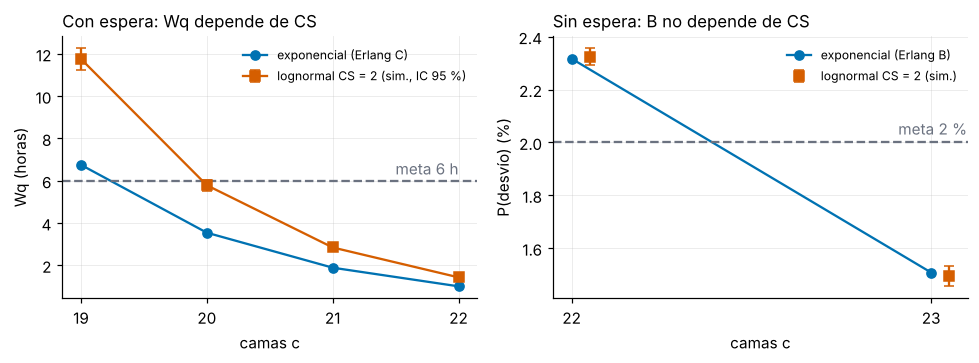

In [8]:
# 3.1b Cuánto cambia cada meta con la variabilidad: razón CS=2 / exponencial en el mismo c
base_B = {k: T.erlang_b(k, lam / mu) for k in (cB - 1, cB)}
base_W = {k: T.mmc(lam, mu, k)["Wq_h"] for k in wq_ln}
sens = pd.DataFrame([{"medida": "B (sin espera)", "c": k, "exponencial (teoría)": base_B[k],
                      "CS = 2 (sim.)": verb.query("escenario == '(iii) CS = 2' and meta == 'B <= 2 %' and c == @k")["media"].iloc[0]} for k in base_B] +
                    [{"medida": "Wq h (con espera)", "c": k, "exponencial (teoría)": base_W[k], "CS = 2 (sim.)": wq_ln[k]["media"]} for k in wq_ln])
sens["razón CS2/exp"] = sens["CS = 2 (sim.)"] / sens["exponencial (teoría)"]
RES["3.1b_sensibilidad_CS"] = sens.to_dict("records")
print(sens.round(4).to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(9, 3.4))
ks = sorted(wq_ln)
ax[0].plot(ks, [base_W[k] for k in ks], "o-", color=AZUL, label="exponencial (Erlang C)")
ax[0].errorbar(ks, [wq_ln[k]["media"] for k in ks], yerr=[wq_ln[k]["semiancho"] for k in ks], fmt="s-", color=NARANJA, capsize=3, label="lognormal CS = 2 (sim., IC 95 %)")
ax[0].axhline(META_WQ_H, color=GRIS, ls="--"); ax[0].text(ks[-1], META_WQ_H + 0.3, "meta 6 h", color=GRIS, ha="right")
ax[0].set_xticks(ks); ax[0].set_xlabel("camas c"); ax[0].set_ylabel("Wq (horas)"); ax[0].set_title("Con espera: Wq depende de CS", loc="left"); ax[0].legend(fontsize=8)
kb = [cB - 1, cB]
ax[1].plot(kb, [100 * base_B[k] for k in kb], "o-", color=AZUL, label="exponencial (Erlang B)")
vb = verb.query("escenario == '(iii) CS = 2' and meta == 'B <= 2 %'").sort_values("c")
ax[1].errorbar(vb["c"] + 0.05, 100 * vb["media"], yerr=100 * (vb["ic_sup"] - vb["media"]), fmt="s", color=NARANJA, capsize=3, label="lognormal CS = 2 (sim.)")
ax[1].axhline(100 * META_B, color=GRIS, ls="--"); ax[1].text(kb[-1] + 0.1, 100 * META_B + 0.03, "meta 2 %", color=GRIS, ha="right")
ax[1].set_xticks(kb); ax[1].set_xlabel("camas c"); ax[1].set_ylabel("P(desvío) (%)"); ax[1].set_title("Sin espera: B no depende de CS", loc="left"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "fig_3_1b_sensibilidad_cs.png", dpi=160); plt.show()

## Task 3.1c: cierre de $k_{off}$ = 6 camas durante 7 días
Con la recomendación ($c$ = 23, sin espera), la capacidad baja a 17 camas entre $t_0$ y $t_0+7$. Nadie es expulsado: solo se desvía a quien llega cuando las camas ocupadas son al menos la capacidad vigente. Se usa `llegadas_variables.simular_perdida`, con λ constante generada por adelgazamiento (validada en `tests/test_llegadas_variables.py`).
- Arranque: el hospital empieza vacío y el cierre ocurre en $t_0$ = 100 días, después del calentamiento justificado en el Task 1.4.
- Medida: probabilidad de que un paciente que llega durante el cierre sea desviado. Se estima, réplica por réplica, como la fracción del tiempo de $[t_0, t_0+7)$ con las camas vigentes llenas (por PASTA, las llegadas de Poisson ven ese estado), con 2000 réplicas. Se comprueba con el total de desviados entre el total de llegadas. Referencia cuasiestacionaria: $B(17, 15.2)$.
- Contingencia: el menor número de camas temporales $k$ (capacidad $17+k$ durante el cierre) con el límite superior del IC de 95 % del desvío durante el cierre ≤ 2 %.

In [9]:
# 3.1c Cierre de k_off camas en [T0, T0 + TB): probabilidad de desvío durante el cierre, una observación por réplica
T0, TB, NREP_C = 100.0, 7.0, 2000
HZ_C = T0 + TB + 30.0                              # 30 días después de reabrir para ver la recuperación
VENT = [T0 - 7, T0, T0 + TB, T0 + TB + 7]          # 7 días antes, el cierre y 7 días después

# Resume una réplica. La medida principal es la fracción del tiempo del cierre con las camas vigentes llenas:
# por PASTA, una llegada de Poisson ve el estado de ese instante, así que su media es Σ desviados / Σ llegadas.
# Se usa en lugar del cociente b/n de cada réplica porque, con unas 27 llegadas, ese cociente queda sesgado
# (las réplicas con más llegadas son también las que más desvían y pesan lo mismo que las demás).
def resumen_cierre(r):
    n, b = LV.conteo_por_ventana(r, VENT)
    lleno_v, _ = LV.tiempo_lleno_por_ventana(r, VENT)
    lleno, _ = LV.tiempo_lleno_por_ventana(r, np.arange(T0 - 7, HZ_C + 1e-9, 0.25))
    return {"antes": lleno_v[0], "cierre": lleno_v[1], "despues": lleno_v[2], "n_cierre": n[1], "b_cierre": b[1],
            "cociente_cierre": b[1] / n[1] if n[1] else np.nan, "lleno": lleno}

def correr_cierre(c_, extra, s):
    cierres = [(T0, T0 + TB, k_off - extra)]          # extra = camas temporales que compensan parte del cierre
    return LV.replicar_perdida(NREP_C, s, resumen_cierre, c=c_, horizonte=HZ_C, tasa=LV.tasa_constante(lam),
                               lam_max=lam, mu=mu, cierres=cierres)

cie = {}
cie[(REC, 0)] = correr_cierre(REC, 0, semilla(f"3.1c cierre c={REC}", 8301))
cie[(18, 0)] = correr_cierre(18, 0, semilla("3.1c cierre c=18 (actual)", 8302))
filas = []
for (c_, e), reps in cie.items():
    ic = S.ic_t([r["cierre"] for r in reps]); ica = S.ic_t([r["antes"] for r in reps]); icd = S.ic_t([r["despues"] for r in reps])
    filas.append({"camas": int(c_), "capacidad en el cierre": int(c_ - k_off + e), "B estacionario sin cierre": T.erlang_b(c_, lam / mu),
                  "B cuasiestacionario en el cierre": T.erlang_b(c_ - k_off + e, lam / mu),
                  "desvío 7 d antes": ica["media"], "desvío en el cierre": ic["media"], "IC inf": ic["ic_inf"], "IC sup": ic["ic_sup"],
                  "desvío 7 d después": icd["media"], "comprobación Σb/Σn": sum(r["b_cierre"] for r in reps) / sum(r["n_cierre"] for r in reps),
                  "desviados por cierre": np.mean([r["b_cierre"] for r in reps]), "llegadas por cierre": np.mean([r["n_cierre"] for r in reps])})
tab_c = pd.DataFrame(filas)
for _, f in tab_c.iterrows():
    print(f"- 3.1c c = {f['camas']}: desvío durante el cierre {f['desvío en el cierre']:.4f} [{f['IC inf']:.4f}; {f['IC sup']:.4f}] "
          f"(Σb/Σn = {f['comprobación Σb/Σn']:.4f}; B({f['capacidad en el cierre']}) = {f['B cuasiestacionario en el cierre']:.4f}); "
          f"antes {f['desvío 7 d antes']:.4f} (B({f['camas']}) = {f['B estacionario sin cierre']:.4f}); después {f['desvío 7 d después']:.4f}; "
          f"{f['desviados por cierre']:.2f} desviados de {f['llegadas por cierre']:.1f} llegadas")
tab_c.round(4)

- 3.1c c = 23.0: desvío durante el cierre 0.1545 [0.1484; 0.1606] (Σb/Σn = 0.1564; B(17.0) = 0.1188); antes 0.0145 (B(23.0) = 0.0151); después 0.0097; 4.16 desviados de 26.6 llegadas
- 3.1c c = 18.0: desvío durante el cierre 0.4166 [0.4091; 0.4241] (Σb/Σn = 0.4145; B(12.0) = 0.3164); antes 0.0873 (B(18.0) = 0.0911); después 0.0497; 11.10 desviados de 26.8 llegadas


,camas,capacidad en el cierre,B estacionario sin cierre,B cuasiestacionario en el cierre,desvío 7 d antes,desvío en el cierre,IC inf,IC sup,desvío 7 d después,comprobación Σb/Σn,desviados por cierre,llegadas por cierre
0,23,17,0.0151,0.1188,0.0145,0.1545,0.1484,0.1606,0.0097,0.1564,4.1595,26.599
1,18,12,0.0911,0.3164,0.0873,0.4166,0.4091,0.4241,0.0497,0.4145,11.0965,26.773


In [10]:
# 3.1c Contingencia: menor número de camas temporales durante el cierre con IC sup del desvío <= 2 %
cont = []
for e in range(0, k_off + 1):
    if (REC, e) not in cie:
        cie[(REC, e)] = correr_cierre(REC, e, semilla(f"3.1c contingencia c={REC} extra={e}", 8310 + e))
    reps = cie[(REC, e)]
    ic = S.ic_t([r["cierre"] for r in reps])
    cont.append({"camas temporales": e, "capacidad en el cierre": REC - k_off + e, "desvío en el cierre": ic["media"],
                 "IC inf": ic["ic_inf"], "IC sup": ic["ic_sup"], "cumple (IC sup <= 2 %)": ic["ic_sup"] <= META_B,
                 "comprobación Σb/Σn": sum(r["b_cierre"] for r in reps) / sum(r["n_cierre"] for r in reps),
                 "desviados por cierre": np.mean([r["b_cierre"] for r in reps])})
cont = pd.DataFrame(cont)
e_min = int(cont.loc[cont["cumple (IC sup <= 2 %)"], "camas temporales"].min())
RES["3.1c_cierre"] = tab_c.to_dict("records"); RES["3.1c_contingencia"] = cont.to_dict("records"); RES["3.1c_camas_temporales_min"] = e_min
tab_c.to_csv(DAT / "task3_1c_cierre.csv", index=False); cont.to_csv(DAT / "task3_1c_contingencia.csv", index=False)
print(f"- 3.1c menor número de camas temporales durante el cierre para desvío <= 2 % (IC sup): {e_min}")
cont.round(4)

- 3.1c menor número de camas temporales durante el cierre para desvío <= 2 % (IC sup): 6


,camas temporales,capacidad en el cierre,desvío en el cierre,IC inf,IC sup,cumple (IC sup <= 2 %),comprobación Σb/Σn,desviados por cierre
0,0,17,0.1545,0.1484,0.1606,False,0.1564,4.1595
1,1,18,0.1141,0.1090,0.1192,False,0.1153,3.0605
2,2,19,0.0883,0.0835,0.0931,False,0.0900,2.4285
3,3,20,0.0579,0.0541,0.0617,False,0.0594,1.5935
4,4,21,0.0397,0.0366,0.0429,False,0.0408,1.0870
5,5,22,0.0249,0.0225,0.0273,False,0.0250,0.6630
6,6,23,0.0133,0.0117,0.0150,True,0.0140,0.3685


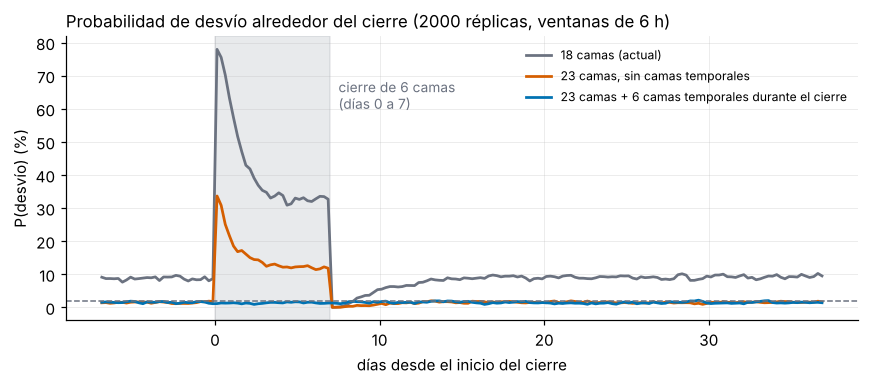

In [11]:
# 3.1c Figura: fracción del tiempo con las camas llenas (≈ P(bloqueo) por PASTA) alrededor del cierre
tt = np.arange(T0 - 7, HZ_C, 0.25) + 0.125 - T0
fig, ax = plt.subplots(figsize=(8, 3.6))
for (c_, e), col, lab in [((18, 0), GRIS, "18 camas (actual)"), ((REC, 0), NARANJA, f"{REC} camas, sin camas temporales"),
                          ((REC, e_min), AZUL, f"{REC} camas + {e_min} camas temporales durante el cierre")]:
    m = np.mean([r["lleno"] for r in cie[(c_, e)]], axis=0)
    ax.plot(tt, 100 * m, color=col, lw=1.8, label=lab)
ax.axvspan(0, TB, color=GRIS, alpha=0.15); ax.text(TB + 0.5, 60, "cierre de 6 camas\n(días 0 a 7)", ha="left", color=GRIS, fontsize=9)
ax.axhline(100 * META_B, color=GRIS, ls="--", lw=1)
ax.set_xlabel("días desde el inicio del cierre"); ax.set_ylabel("P(desvío) (%)")
ax.set_title(f"Probabilidad de desvío alrededor del cierre ({NREP_C} réplicas, ventanas de 6 h)", loc="left"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "fig_3_1c_cierre.png", dpi=160); plt.show()

In [12]:
# Guardar resultados y semillas del Task 3
pd.DataFrame(SEMILLAS).to_csv(DAT / "task3_semillas.csv", index=False)
(DAT / "task3_resultados.json").write_text(json.dumps(RES, indent=2, ensure_ascii=False,
    default=lambda o: o.item() if hasattr(o, "item") else (o.tolist() if hasattr(o, "tolist") else str(o))))
print("- Guardado: resultados/datos/task3_resultados.json, task3_semillas.csv y CSV de 3.1a-c")

- Guardado: resultados/datos/task3_resultados.json, task3_semillas.csv y CSV de 3.1a-c
